# Domain wall mobility in the Landau-Lifshitz-Baryakhtar equation

A check of the `llbar` driver against a result that does not come from a simulation.

**Reference:** V. G. Bar'yakhtar, *Phenomenological description of relaxation processes in magnetic materials*, Zh. Eksp. Teor. Fiz. **87**, 1501 (1984) [Sov. Phys. JETP **60**, 863 (1984)], equations (41), (48) and (51).

Bar'yakhtar adds to the local relaxation of the Landau-Lifshitz equation a term of exchange origin, which depends on the spatial derivatives of the effective field. A wall of width $\Delta$ then sees the relaxation constant

$$\alpha_\mathrm{eff} = \alpha + \frac{\beta}{3\Delta^2},$$

where $\alpha$ is the local (relativistic) constant and $\beta$ the exchange one, which in Fidimag has the units of m$^2$. Below the Walker field $H_W = \alpha_\mathrm{eff} H_k / 2$ a Bloch wall driven by a field $H$ along the easy axis then moves at

$$v = \frac{\gamma \Delta H}{\alpha_\mathrm{eff}} .$$

The same $\beta$ damps a spin wave of wave vector $k$ by $\alpha + \beta k^2$ (eqs. 45 and 47; checked in `tests/test_baryakhtar.py`). The factor $1/3$ is the average of $k^2$ over the wall profile.

The formula is a first-order result for a rigid wall, so we expect it to hold while $\beta/(3\Delta^2)$ is not much larger than $\alpha$, and to drift away beyond that.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from fidimag.common import CuboidMesh
from fidimag.micro import Sim, UniformExchange, UniaxialAnisotropy, Zeeman

mu0 = 4e-7 * np.pi
A, Ms, K, K_perp = 1.3e-11, 8e5, 5e5, 2.5e5       # exchange, saturation, easy axis (x), hard axis (z)
gamma, alpha = 2.211e5, 0.02
Delta = np.sqrt(A / K)                             # wall width
H_k = 2 * K_perp / (mu0 * Ms)                      # hard-axis field
print('wall width = %.2f nm, H_k = %.3g A/m' % (Delta * 1e9, H_k))

wall width = 5.10 nm, H_k = 4.97e+05 A/m


## The simulation

A 1D chain of 300 cells of 1 nm, with a head-to-head wall at the centre. The easy axis $K$ along $x$ fixes $\Delta = \sqrt{A/K}$ and the hard axis $K_\perp$ along $z$ gives a Walker field. (Without a hard axis there is no steady regime: the wall precesses, with $v = \alpha\gamma\Delta H/(1+\alpha^2)$.)

The wall position is taken from the integral of $m_x$, and the velocity is the slope of that position over the second half of the run, after the wall has tilted into its steady motion.

In [2]:
NX, DX = 300, 1e-9

def wall_velocity(beta, H, T=3e-9, samples=12):
    mesh = CuboidMesh(nx=NX, ny=1, nz=1, dx=DX * 1e9, dy=DX * 1e9, dz=DX * 1e9, unit_length=1e-9)
    sim = Sim(mesh, name='wall', driver='llbar')
    sim.set_Ms(Ms)
    sim.driver.gamma, sim.alpha, sim.driver.beta, sim.driver.default_c = gamma, alpha, beta, 0.0
    x = (np.arange(NX) + 0.5) * DX
    m = np.zeros((NX, 3))
    m[:, 0] = -np.tanh((x - NX * DX / 2) / Delta)
    m[:, 1] = 1 / np.cosh((x - NX * DX / 2) / Delta)
    sim.set_m(m.reshape(-1))
    sim.add(UniformExchange(A))
    sim.add(UniaxialAnisotropy(K, axis=(1, 0, 0)))
    sim.add(UniaxialAnisotropy(-K_perp, axis=(0, 0, 1)))
    sim.add(Zeeman((H, 0, 0)))
    sim.driver.set_tols(rtol=1e-6, atol=1e-9)
    ts, qs, snaps = [], [], []
    for t in np.linspace(0, T, samples + 1):
        if t > 0:
            sim.driver.run_until(t)
        ts.append(t)
        snaps.append(sim.spin.reshape(-1, 3).copy())
        qs.append((NX * DX + DX * np.sum(sim.spin.reshape(-1, 3)[:, 0])) / 2)
    ts, qs = np.array(ts), np.array(qs)
    late = ts >= T / 2
    return np.polyfit(ts[late], qs[late], 1)[0], ts, qs, snaps

## Sweep the exchange relaxation

`ratio` is $\beta / (3\Delta^2\alpha)$: the exchange relaxation of the wall in units of the local one. The field is a tenth of the Walker field without $\beta$, which is below it for every $\beta$ here.

In [3]:
H = 0.1 * alpha * H_k / 2
ratios = [0.0, 0.5, 1.0, 2.0, 3.0]
runs = {}
for ratio in ratios:
    beta = ratio * 3 * Delta ** 2 * alpha
    a_eff = alpha + beta / (3 * Delta ** 2)
    v, ts, qs, snaps = wall_velocity(beta, H)
    runs[ratio] = dict(v=v, predicted=gamma * Delta * H / a_eff, ts=ts, qs=qs, snaps=snaps)
    print('beta/(3 Delta^2 alpha) = %.1f: v = %5.2f m/s, Baryakhtar %5.2f m/s' % (ratio, v, runs[ratio]['predicted']))

beta/(3 Delta^2 alpha) = 0.0: v = 27.61 m/s, Baryakhtar 28.04 m/s


beta/(3 Delta^2 alpha) = 0.5: v = 18.57 m/s, Baryakhtar 18.69 m/s


beta/(3 Delta^2 alpha) = 1.0: v = 14.05 m/s, Baryakhtar 14.02 m/s


beta/(3 Delta^2 alpha) = 2.0: v =  9.68 m/s, Baryakhtar  9.35 m/s


beta/(3 Delta^2 alpha) = 3.0: v =  7.60 m/s, Baryakhtar  7.01 m/s


## The wall in motion

Snapshots of the wall without exchange relaxation ($\beta = 0$) and with $\beta/(3\Delta^2) = 3\alpha$, at the same times. With the exchange relaxation the wall moves a quarter as far in the same time. The lower panels show the profile at the end of the run: the field tilts the wall out of the easy-axis plane towards the hard axis $z$, which is the $m_z$ component, and the tilt is what the hard axis balances against the drive.

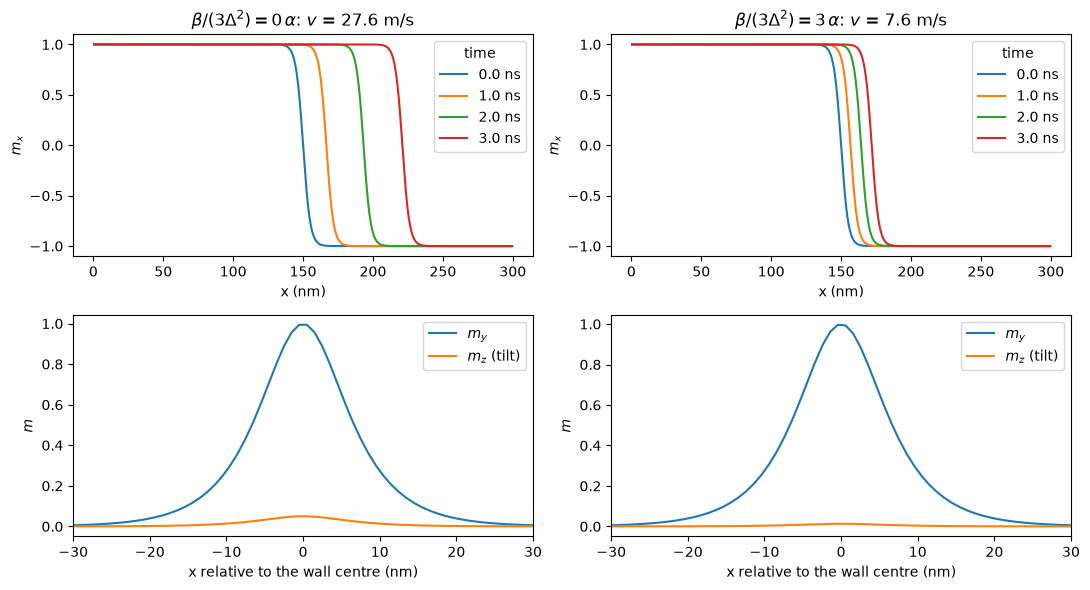

In [4]:
x = (np.arange(NX) + 0.5) * DX * 1e9
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex='row')
for col, ratio in enumerate((0.0, 3.0)):
    r = runs[ratio]
    for i in (0, 4, 8, 12):
        axes[0, col].plot(x, r['snaps'][i][:, 0], label='%.1f ns' % (r['ts'][i] * 1e9))
    axes[0, col].set_title(r'$\beta/(3\Delta^2) = %g\,\alpha$: $v$ = %.1f m/s' % (ratio, r['v']))
    axes[0, col].set_ylabel('$m_x$'); axes[0, col].legend(title='time')
    final = r['snaps'][-1]
    q = r['qs'][-1] * 1e9
    axes[1, col].plot(x - q, final[:, 1], label='$m_y$')
    axes[1, col].plot(x - q, final[:, 2], label='$m_z$ (tilt)')
    axes[1, col].set_xlim(-30, 30)
    axes[1, col].set_xlabel('x relative to the wall centre (nm)'); axes[1, col].set_ylabel('$m$'); axes[1, col].legend()
axes[0, 0].set_xlabel('x (nm)'); axes[0, 1].set_xlabel('x (nm)')
plt.tight_layout()

## Velocity against the exchange relaxation

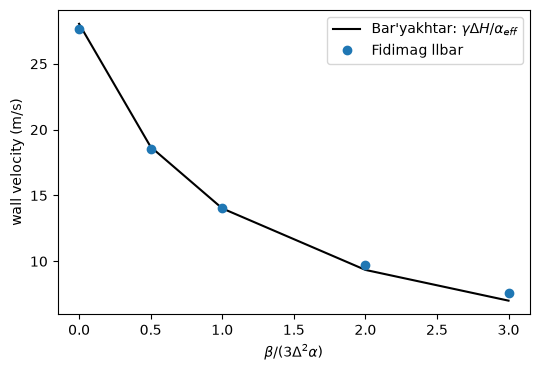

In [5]:
ratios_a = np.array(ratios)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(ratios_a, [runs[r]['predicted'] for r in ratios], 'k-', label=r"Bar'yakhtar: $\gamma\Delta H/\alpha_{eff}$")
ax.plot(ratios_a, [runs[r]['v'] for r in ratios], 'o', label='Fidimag llbar')
ax.set_xlabel(r'$\beta / (3\Delta^2\alpha)$'); ax.set_ylabel('wall velocity (m/s)'); ax.legend()
plt.tight_layout()

## Reading the result

The wall slows as the exchange relaxation grows, as $1/\alpha_\mathrm{eff}$, and the simulation agrees with Bar'yakhtar's formula to about 1 % up to $\beta/(3\Delta^2) = \alpha$. Beyond that the simulated wall is faster than the formula, with a deviation that grows roughly as $\beta^2$. That is expected for a first-order result which assumes the wall keeps its profile; it is not a discrepancy to chase.

The offset at $\beta = 0$ (about 1 % low) is from the tilt of the wall, which narrows it slightly, and from the finite cell size.